## Set up coding environment

In [1]:
import os
os.getcwd()

'c:\\Users\\MEGHNA\\Documents\\GitHub\\ResearchProject_1\\LearnedHDC-Interpretability\\notebooks\\final_viz'

In [2]:
os.chdir('../..')
os.getcwd()

'c:\\Users\\MEGHNA\\Documents\\GitHub\\ResearchProject_1\\LearnedHDC-Interpretability'

## Plain HDC Classifier
Small working example of initialising an HDC classifier pipeline and training the classifier block.

In [3]:
import src.core.datasets as datasets
import src.core.common_func_2 as common_func
import numpy as np
import matplotlib.pyplot as plt

PATH_PREFIX:  c:\Users\MEGHNA\Documents\GitHub\ResearchProject_1\LearnedHDC-Interpretability\src\core\..\..


In [4]:
#parameters for training procedure
dataset = "pamap2" #audio signals

num_quantiles = 21 
dimensionality = 10000

epochs = 2500 #50

In [5]:
#load dataset
train_data, train_labels, test_data, test_labels, num_classes = datasets.load_dataset(dataset) #do we do any splitting in the train data??
train_data.shape

pamap2_train.choir_dat	16384 samples	27 features	5 classes
pamap2_test.choir_dat	16384 samples	27 features	5 classes


(16384, 27)

In [6]:
train_data

array([[-11.96385384,   2.8575592 ,   2.77268696, ...,   0.21407606,
         -0.72226119,  -0.30490404],
       [ -3.43616676,   6.97501326,   9.06113243, ...,  -0.26762444,
         -0.6144461 ,   0.21546975],
       [ -8.66847515,   3.91429496,   0.31604016, ...,  -0.1342378 ,
         -0.11319052,   0.02616495],
       ...,
       [ -9.3164959 ,   1.28284752,   2.44129467, ...,   0.52583373,
         -0.21522282,   0.05540923],
       [ -1.02329123,   0.07891689,   7.1095295 , ...,   0.24893042,
         -0.02306343,   0.03838112],
       [-10.67445469,   2.3416028 ,   3.22997665, ...,   0.27185047,
         -0.73481929,  -0.27687037]])

In [7]:
np.unique(train_labels)

array([0, 1, 2, 3, 4])

In [8]:
#make a class mapping with the indexes
import string
alphabets = list(string.ascii_uppercase)
class_mapping = {index: alphabet for index,alphabet in zip(list(np.unique(train_labels)),alphabets)}
class_mapping

{0: 'A',
 1: 'B',
 2: 'C',
 3: 'D',
 4: 'E',
 5: 'F',
 6: 'G',
 7: 'H',
 8: 'I',
 9: 'J',
 10: 'K',
 11: 'L',
 12: 'M',
 13: 'N',
 14: 'O',
 15: 'P',
 16: 'Q',
 17: 'R',
 18: 'S',
 19: 'T',
 20: 'U',
 21: 'V',
 22: 'W',
 23: 'X',
 24: 'Y',
 25: 'Z'}

In [8]:
#discretise range of all values of train data. Discretised into bins according to num_quantiles
num_features = len(train_data[0])
num_classes = len(np.unique(train_labels))
print("number of classes:",num_classes)
mins = np.min(train_data, axis=0) #shape (617,)
print('minimum value in train data:',mins.shape)
maxes = np.max(train_data, axis=0) #shape (617,)
print('maximum value in train data:',maxes.shape)
shifted_maxes = maxes-mins # defines the size of the intervals for the 21 bins
#shifted maxes as in the difference/range? would this vector be used for nudging missclassified samples?

quantiles_edges = [mins] #quantiles edges : boundaries for the bins, 21 X 617 matrix?
print('quantile edges to start with',len(quantiles_edges))

for i in range(num_quantiles-1): #0-20, 21 quantiles

    quantiles_edges.append(quantiles_edges[-1]+(shifted_maxes/(num_quantiles-1))) 
    # print('new quantile_edges appended',len(quantiles_edges))

quantiles_edges = np.array(quantiles_edges) 
print('final quantile_edges shape',quantiles_edges.shape)
quantile_midpoints = np.transpose(quantiles_edges[:-1,:] + (((shifted_maxes)/(num_quantiles-1))/2)) #why the transpose?
#the centre value of each quantile is taken as the representative of the whole group. why centre?

number of classes: 5
minimum value in train data: (27,)
maximum value in train data: (27,)
quantile edges to start with 1
final quantile_edges shape (21, 27)


In [10]:
#read the model in
## load trained model
import pickle as pkl
model_path = os.path.join(os.getcwd(),'trained_models',dataset,'twilight-pine-10855_memories.pkl')
with open(model_path, "rb") as f:
    trained_model = pkl.load(f)

In [11]:
trained_model

{'cim': array([[-1,  1, -1, ...,  1,  1, -1],
        [-1,  1, -1, ...,  1,  1, -1],
        [-1,  1, -1, ...,  1,  1, -1],
        ...,
        [ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1]], dtype=int8),
 'im': array([[ 1,  1, -1, ..., -1,  1,  1],
        [ 1, -1,  1, ...,  1, -1,  1],
        [ 1, -1, -1, ...,  1,  1,  1],
        ...,
        [-1,  1,  1, ...,  1,  1,  1],
        [-1,  1, -1, ...,  1,  1, -1],
        [-1,  1,  1, ...,  1,  1,  1]], dtype=int8),
 'am': array([[ 1,  1, -1, ..., -1, -1,  1],
        [ 1,  1, -1, ..., -1,  1,  1],
        [ 1,  1,  1, ..., -1,  1,  1],
        ...,
        [ 1,  1, -1, ..., -1, -1,  1],
        [ 1,  1,  1, ..., -1, -1,  1],
        [ 1,  1,  1, ..., -1,  1,  1]], dtype=int8)}

In [9]:
#Generate static Continuous Item Memory (CIM) to represent feature values range and ID Memory (IM) to represent feature IDs.
cim = common_func.generate_CIM(num_quantiles, dimensionality)#trained_model['cim'] #21 x 10k
im = common_func.generate_IM(num_features, dimensionality)#trained_model['im'] #617 x 10k

In [10]:
#CIM shape defined by number of quantiles and dimensionality (one HV per quantile) 
# #how do u get 1 hv per quantile? is quantile the same thing as levels? that's where the quantile midpoints come into picture?
cim.shape

(21, 10000)

In [11]:
#IM shape defined by number of features and dimensionality (one HV per feature)
im.shape

(27, 10000)

In [12]:
#Encode the train and test data (convert each data sample into an HV).
#why do we need quantile midpoint? is it something like we want to keep all the training points close to a center so that they don't become outliers? 
#is this some sort of normalization? No, it's the representative for each quantile
train_HVs = common_func.encode_as_HVs_record_based(train_data, cim, im, quantile_midpoints)
test_HVs = common_func.encode_as_HVs_record_based(test_data, cim, im, quantile_midpoints)

In [13]:
#compute initial class bundles by bundling (elementwise sum) samples of respective classes into one bundle per class.
class_bundles = common_func.initialise_prototype_bundles(train_HVs, train_labels) # [+2,+1, 0...]

In [14]:
#pass class bundles through sign function to change from integer to bipolar representation. bipolar version is what is used for classification; bundles only used for training.
class_prototypes = common_func.rand_sign(class_bundles) #the values in the class_bundles are >1 due to the bundling

In [15]:
#evaluate test accuracy before training. #how does this work without training?
initial_test_acc = common_func.evaluate_HDC(test_HVs, class_prototypes, test_labels)

In [16]:
initial_test_acc

0.943603515625

In [17]:
train_HVs.shape

(16384, 10000)

In [18]:
train_accs = [common_func.evaluate_HDC(train_HVs, class_prototypes, train_labels)]
im_dict = {}
im_updates_dict = {}
batch_update_values_dict = {}
for epoch in range(3): #epochs
    if epoch % 10 == 0:
        print(f"epoch {epoch}")

    #one iteration of encoder training
    #get unbinarized im_bundles
    if epoch == 0:
        im_bundles = im
    im_bundles,im_updates, batch_update_values_list = common_func.train_encoder_one_iteration(train_data=train_data, 
                                                        #  train_HVs=train_HVs, 
                                                         train_labels=train_labels, 
                                                         class_prototypes=class_prototypes, 
                                                         cim=cim, im_bundles=im_bundles, quantile_midpoints=quantile_midpoints) #is the input also unbinarized??
    
    #binarize them to make the IM HVs
    updatedd_im_hvs = common_func.rand_sign(im_bundles)

    #store the IM_HVs for analysis later
    print(f'adding im HVs at epoch {epoch} to im_dict')
    im_dict[f'epoch_{epoch}'] = updatedd_im_hvs
    im_updates_dict[f'epoch_{epoch}'] = im_updates
    batch_update_values_dict[f'epoch_{epoch}'] = batch_update_values_list   
    #encode the training samples with the new IM HVs
    updated_train_HVs = common_func.encode_as_HVs_record_based(train_data, cim, updatedd_im_hvs, quantile_midpoints)
    
    #update class bundles
    class_bundles = common_func.train_classifier_one_iteration(updated_train_HVs, train_labels, class_bundles)
    
    #sign class bundles (as before)
    class_prototypes = common_func.rand_sign(class_bundles)

    #evaluate train accuracy (can be used to decide when to stop training, but for now we are just logging it)
    train_accs.append(common_func.evaluate_HDC(train_HVs, class_prototypes, train_labels))
    print(f"train accuracy at epoch {epoch} is {train_accs[-1]}")
final_test_acc = common_func.evaluate_HDC(test_HVs, class_prototypes, test_labels)
print(f"final test accuracy is {final_test_acc}")


epoch 0
adding im HVs at epoch 0 to im_dict
train accuracy at epoch 0 is 0.97015380859375
adding im HVs at epoch 1 to im_dict
train accuracy at epoch 1 is 0.969970703125
adding im HVs at epoch 2 to im_dict
train accuracy at epoch 2 is 0.97308349609375
final test accuracy is 0.95074462890625


Text(0.5, 0, 'Epoch')

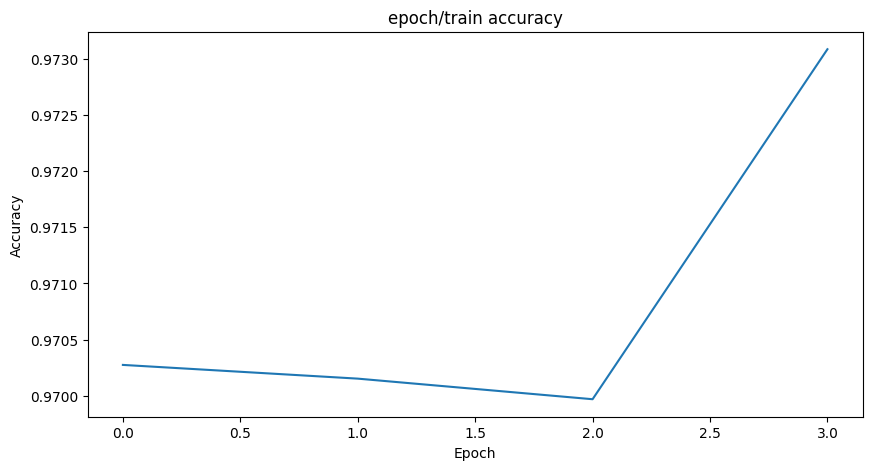

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(train_accs)#accs_log
plt.title("epoch/train accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")

In [20]:
im_dict['epoch_2'].shape

(27, 10000)

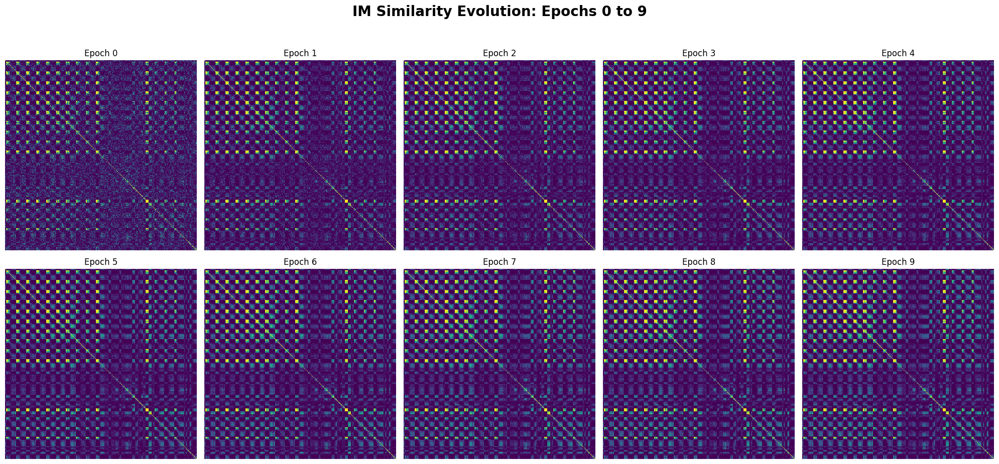

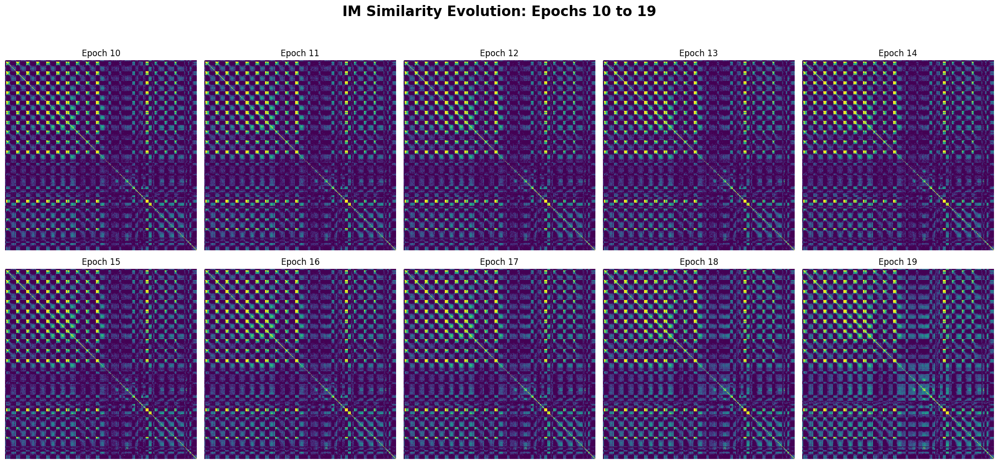

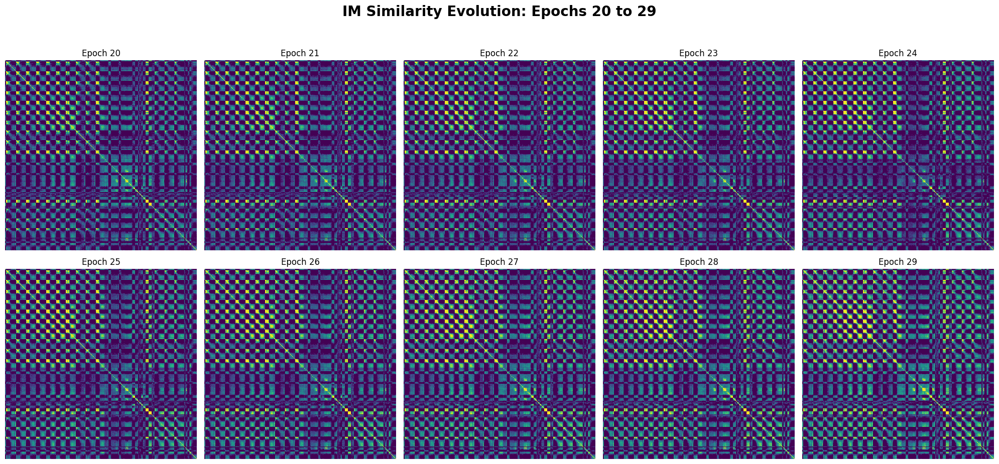

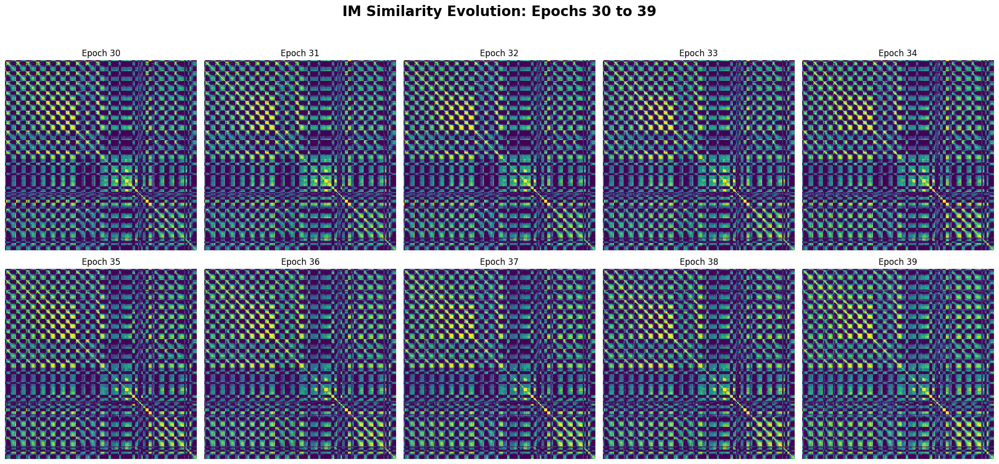

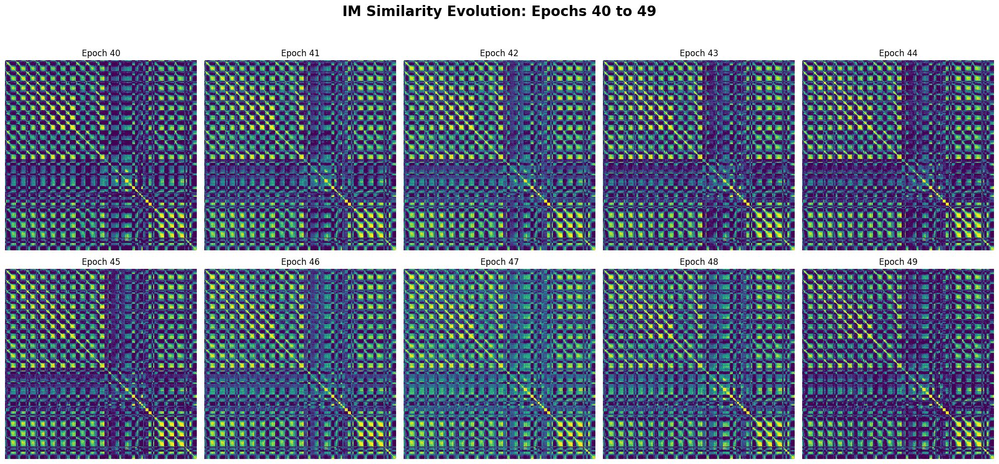

In [29]:
#plot the IMs
import seaborn as sns
import scipy.spatial as sp
def plot_epoch_similarity_evolution(im_history, batch_size=10):
    """
    Plots a grid of cosine similarity heatmaps for the Item Memory across epochs.
    
    Args:
        im_history: List or array of shape (50, 617, 10000)
        clusters_list: Optional list of feature indices to highlight (same as cluster_heatmap.py)
        batch_size: Number of subplots per figure (default 10)
    """
    n_epochs = len(im_history)
    # n_features = im_history['epoch_0'].shape[0]
    
    # Iterate through epochs in batches to maintain readability
    for batch_start in range(0, n_epochs, batch_size):
        batch_end = min(batch_start + batch_size, n_epochs)
        # current_batch_size = batch_end - batch_start
        
        # Create a 2x5 grid for each batch of 10
        rows = 2
        cols = 5
        fig, axes = plt.subplots(rows, cols, figsize=(20, 10))
        axes = axes.flatten()
        
        fig.suptitle(f"IM Similarity Evolution: Epochs {batch_start} to {batch_end-1}", 
                     fontsize=20, fontweight='bold', y=0.95)

        for i, epoch_idx in enumerate(range(batch_start, batch_end)):
            ax = axes[i]
            im_epoch = im_history[f'epoch_{epoch_idx}']
            
            # 1. Compute Cosine Similarity Matrix (Efficiently)
            # Norms for each feature vector (dim: 617)
            # norms = np.linalg.norm(im_epoch, axis=1, keepdims=True)
            # Dot product divided by product of norms
            sim_matrix = 1 - sp.distance.cdist(im_epoch, im_epoch, 'cosine') #np.dot(im_epoch, im_epoch.T) / (np.dot(norms, norms.T) + 1e-9)
            
            # 2. Plot Heatmap
            # We use 'magma' to match your previous visual style
            sns.heatmap(
                sim_matrix, 
                ax=ax, 
                cmap='viridis', 
                cbar=False,  # Hide individual colorbars to save space
                xticklabels=False, 
                yticklabels=False,
                vmin=0, 
                vmax=np.percentile(sim_matrix, 99) # Robust scaling for contrast
            )
            
            ax.set_title(f"Epoch {epoch_idx}", fontsize=12)
            
            # 3. Optional: Add Cluster Boundary Overlays if clusters_list is provided
            # This helps see if "blocks" are forming within your predefined clusters
            # if clusters_list:
            #     for cluster in clusters_list:
            #         start, end = min(cluster), max(cluster)
            #         rect = plt.Rectangle((start, start), end-start, end-start, 
            #                               fill=False, color='cyan', lw=0.5, alpha=0.5)
            #         ax.add_patch(rect)

        # Remove empty subplots if the last batch is smaller than 10
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])
            
        plt.tight_layout(rect=[0, 0.03, 1, 0.92])
        plt.show()

plot_epoch_similarity_evolution(im_history=im_dict, batch_size=10)


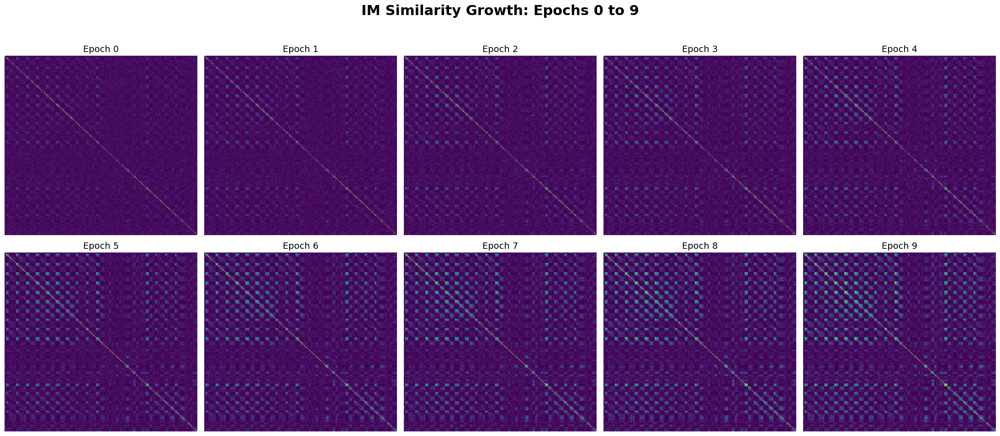

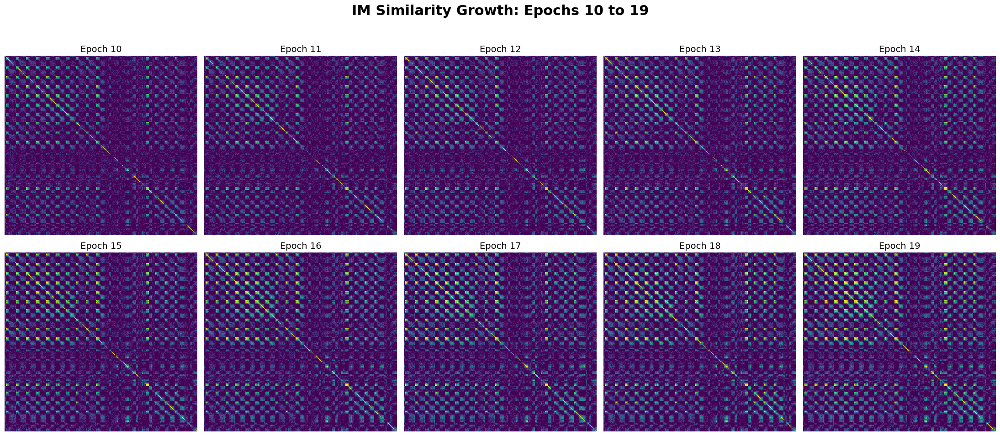

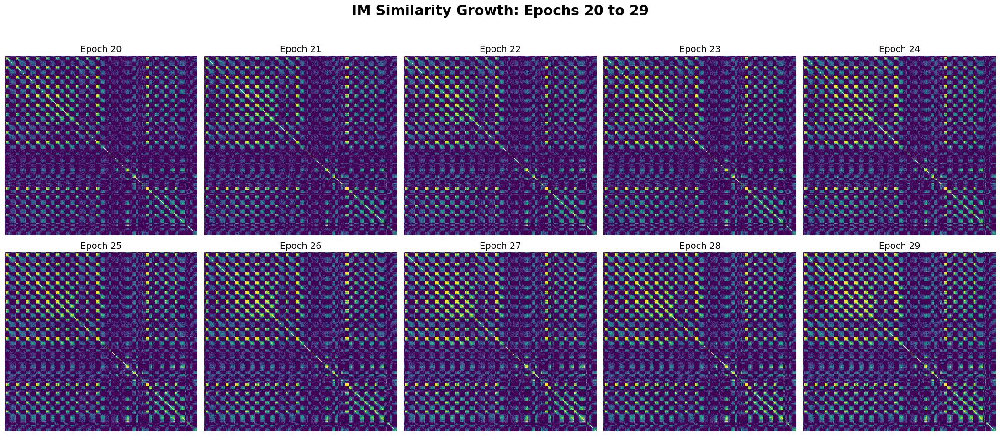

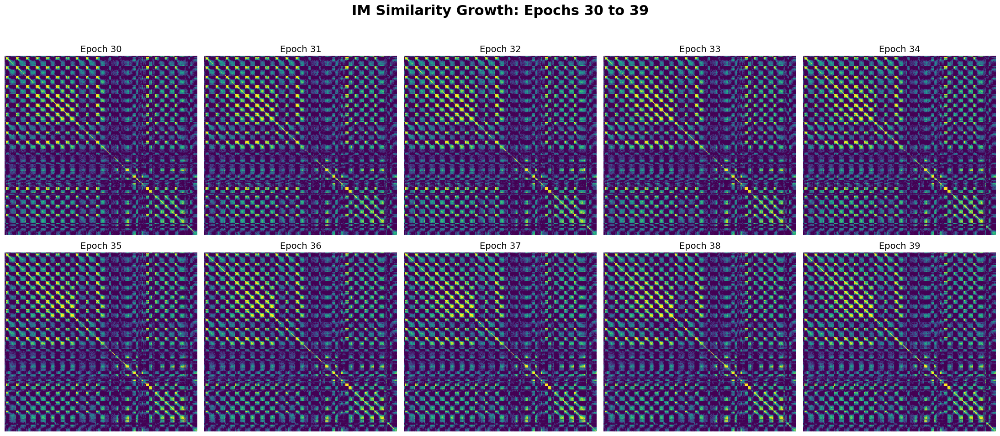

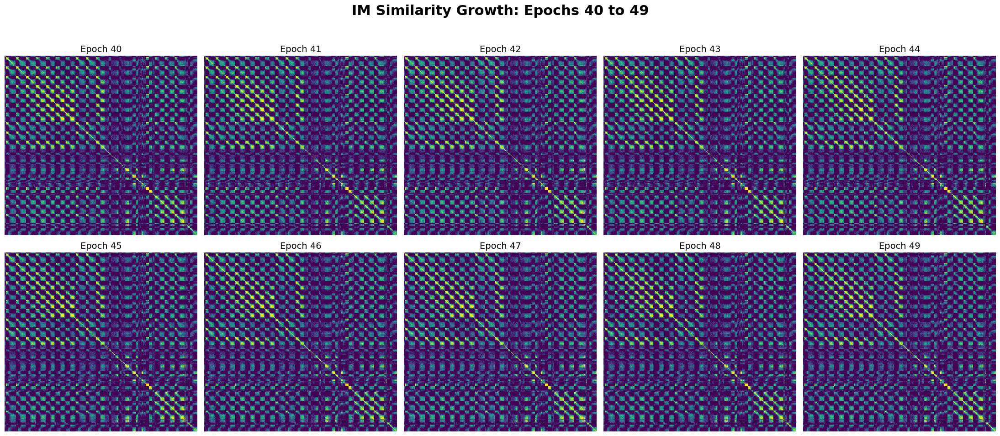

In [22]:
import seaborn as sns
import scipy.spatial as sp

def plot_epoch_similarity_evolution(im_history, batch_size=10, cmap='viridis'):
    """
    Plots a grid of cosine similarity heatmaps for the Item Memory across epochs.
    
    Args:
        im_history: Dictionary or list of IM matrices.
        batch_size: Number of subplots per figure.
        cmap: 'magma' is recommended for HDC to hide orthogonal noise.
    """
    # Handle both dict and list inputs
    if isinstance(im_history, dict):
        epochs = sorted(im_history.keys(), key=lambda x: int(x.split('_')[1]))
        n_epochs = len(epochs)
    else:
        n_epochs = len(im_history)
        epochs = list(range(n_epochs))

    # Calculate a global VMAX based on the final epoch to show actual growth
    final_key = epochs[-1]
    final_im = im_history[final_key] if isinstance(im_history, dict) else im_history[-1]
    final_sim = 1 - sp.distance.cdist(final_im, final_im, 'cosine')
    global_vmax = np.percentile(final_sim, 99.5) 

    for batch_start in range(0, n_epochs, batch_size):
        batch_end = min(batch_start + batch_size, n_epochs)
        fig, axes = plt.subplots(2, 5, figsize=(22, 10))
        axes = axes.flatten()
        
        fig.suptitle(f"IM Similarity Growth: Epochs {batch_start} to {batch_end-1}", 
                     fontsize=22, fontweight='bold', y=0.98)

        for i, epoch_idx in enumerate(range(batch_start, batch_end)):
            ax = axes[i]
            key = epochs[epoch_idx]
            im_epoch = im_history[key] if isinstance(im_history, dict) else im_history[epoch_idx]
            
            sim_matrix = 1 - sp.distance.cdist(im_epoch, im_epoch, 'cosine')
            
            # Use global_vmax so we can see the 'intensity' increase over time
            sns.heatmap(
                sim_matrix, 
                ax=ax, 
                cmap=cmap, 
                cbar=False, 
                xticklabels=False, 
                yticklabels=False,
                vmin=0, 
                vmax=global_vmax, 
                rasterized=True
            )
            ax.set_title(f"Epoch {epoch_idx}", fontsize=14)

        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])
            
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

plot_epoch_similarity_evolution(im_history=im_dict, batch_size=10)

In [23]:
im_updates_dict[f'epoch_48'].shape

(617, 10000)

In [24]:
len(batch_update_values_list)

27

In [29]:
## select IM indexes of the most important features from each epoch and plot their similarity to see how they evolve over training.
#generic function
with open(r'C:\Users\MEGHNA\Documents\GitHub\ResearchProject_1\LearnedHDC-Interpretability\src\trained_model_ranked_discriminative_feature_indices.pkl', "rb") as f:
    trained_ranked_feature_indices = pkl.load(f)

with open(r'C:\Users\MEGHNA\Documents\GitHub\ResearchProject_1\LearnedHDC-Interpretability\src\untrained_model_ranked_discriminative_feature_indices.pkl', "rb") as f:
    trained_ranked_feature_indices = pkl.load(f)


def get_epoch_wise_hvs(im_list:list, epoch_history:dict):
    epoch_wise_im_hvs = []
    for epoch, im in epoch_history.items():
        im_epoch = epoch_history[epoch] #get the IM HVs for that epoch        
        ranked_indices = im_epoch[im_list] #get the ranked feature indices for that epoch
        # top_10_indices = ranked_indices[:10] #select the top 10 feature indices
        epoch_wise_im_hvs.append(ranked_indices) #get the corresponding IM HVs and store them
    return epoch_wise_im_hvs # if epoch is 50, then the shape would be (50, 10, 10000) if we select top 10 features

trained_epoch_wise_hvs = get_epoch_wise_hvs(trained_ranked_feature_indices[:10], im_dict)
trained_epoch_wise_hvs[0].shape



(10, 10000)

In [30]:
len(trained_epoch_wise_hvs)

50

In [32]:
#take the first IM HV (corresponding to the most important feature) from each epoch and plot their similarity evolution across epochs to see how the most important feature evolves across training.
#filter the epoch-wise hvs to get the top 1 feature's IM HV across epochs
top_1_epoch_wise_hvs = [epoch_hvs[0] for epoch_hvs in trained_epoch_wise_hvs] #shape (50, 10000)
top_1_epoch_wise_hvs = np.array(top_1_epoch_wise_hvs)
top_1_epoch_wise_hvs[0].shape

(10000,)

In [33]:
top_1_epoch_wise_hvs.shape

(50, 10000)

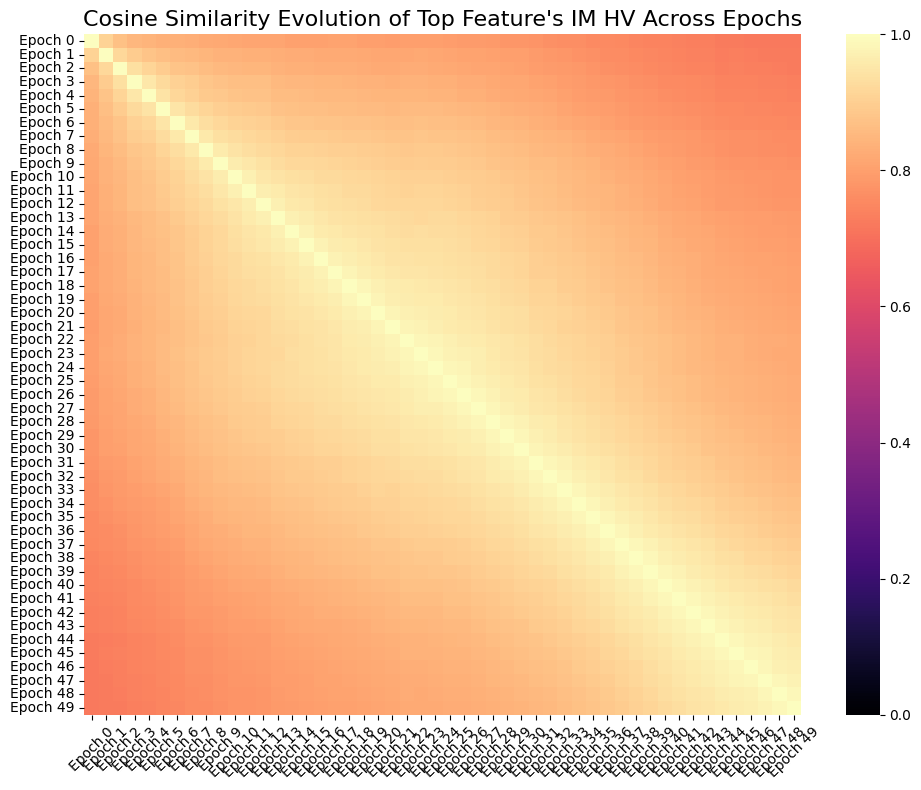

In [35]:
def plot_hv_evolution(hv_history, cmap='viridis'):
    """
    Plots the cosine similarity evolution of a single HV across epochs.
    
    Args:
        hv_history: List or array of shape (n_epochs, dimensionality) containing the HVs across epochs.
        cmap: Color map for the heatmap.
    """
    n_epochs = len(hv_history)
    
    # Compute cosine similarity matrix across epochs
    sim_matrix = 1 - sp.distance.cdist(hv_history, hv_history, 'cosine')
    
    # Plot heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        sim_matrix, 
        cmap=cmap, 
        cbar=True, 
        xticklabels=[f'Epoch {i}' for i in range(n_epochs)], 
        yticklabels=[f'Epoch {i}' for i in range(n_epochs)],
        vmin=0, 
        vmax=np.percentile(sim_matrix, 99.5), 
        rasterized=True
    )
    plt.title("Cosine Similarity Evolution of Top Feature's IM HV Across Epochs", fontsize=16)
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

plot_hv_evolution(top_1_epoch_wise_hvs, cmap='magma')

i see a hotspot in the middle, but what can i even infer from this??

In [36]:
trained_epoch_wise_hvs = np.array(trained_epoch_wise_hvs)

In [37]:
trained_epoch_wise_hvs.shape

(50, 10, 10000)

In [41]:
full_trained_epoch_wise_hvs = get_epoch_wise_hvs(trained_ranked_feature_indices, im_dict)

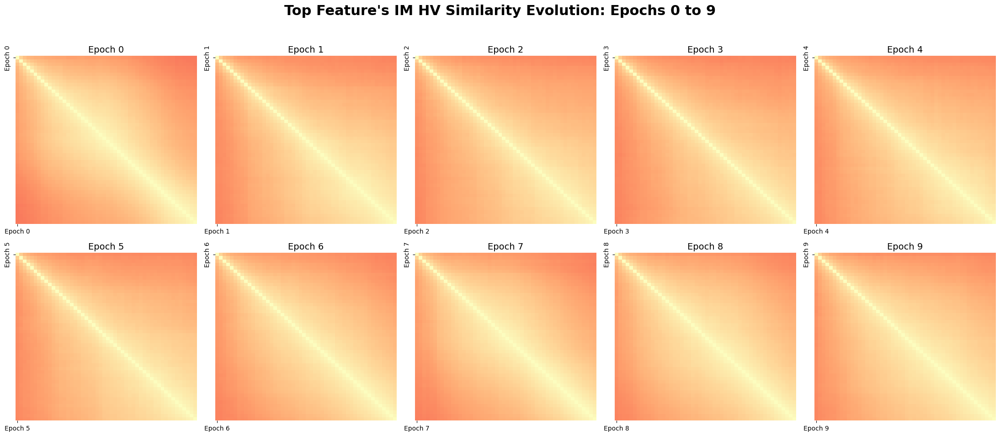

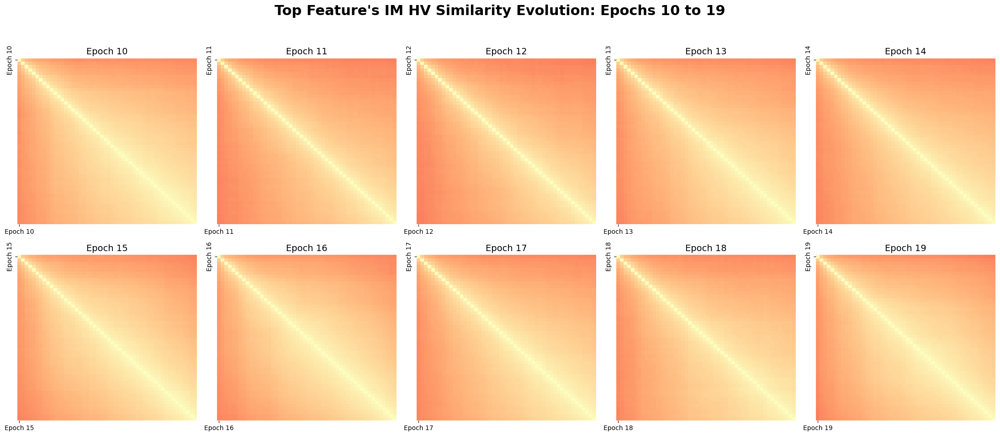

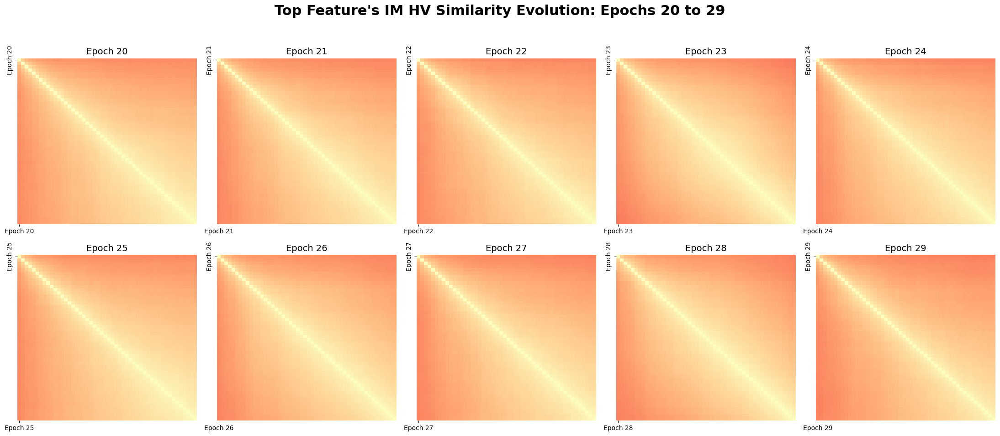

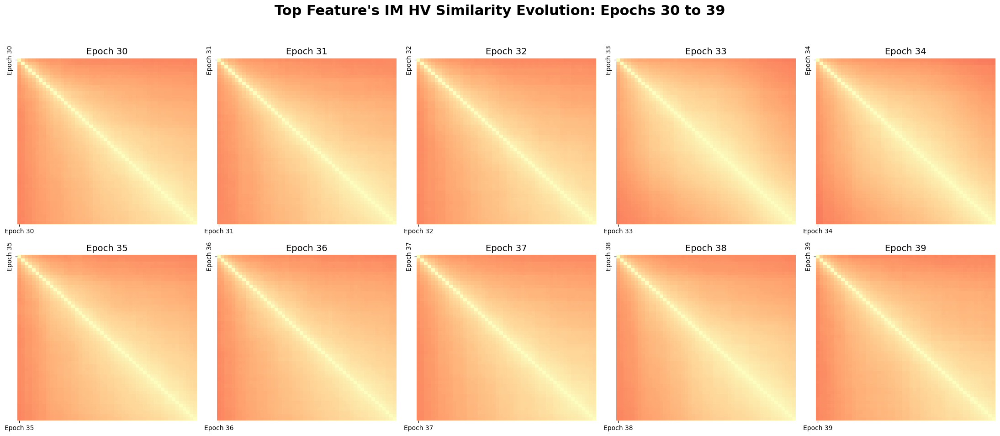

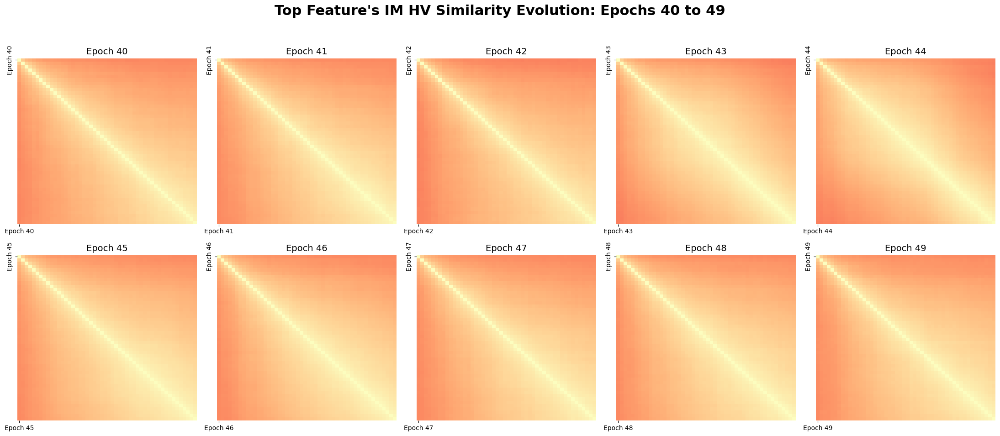

In [42]:
def plot_top_feature_subplots(hv_history, batch_size=10, cmap='viridis'):
    """
    Plots a grid of cosine similarity heatmaps for the evolution of the top feature's IM HV across epochs.
    
    Args:
        hv_history: List or array of shape (n_epochs, dimensionality) containing the HVs across epochs.
        batch_size: Number of subplots per figure.
        cmap: Color map for the heatmap.
    """
    n_epochs = len(hv_history)
    
    for batch_start in range(0, n_epochs, batch_size):
        batch_end = min(batch_start + batch_size, n_epochs)
        fig, axes = plt.subplots(2, 5, figsize=(22, 10))
        axes = axes.flatten()
        
        fig.suptitle(f"Top Feature's IM HV Similarity Evolution: Epochs {batch_start} to {batch_end-1}", 
                     fontsize=22, fontweight='bold', y=0.98)

        for i, epoch_idx in enumerate(range(batch_start, batch_end)):
            ax = axes[i]
            hv_epoch = [epoch_hvs[epoch_idx] for epoch_hvs in hv_history]  #get the top feature's IM HV for each epoch in this batch
            
            # Compute cosine similarity matrix for this epoch
            sim_matrix = 1 - sp.distance.cdist(hv_epoch, hv_epoch, 'cosine')
            
            sns.heatmap(
                sim_matrix, 
                ax=ax, 
                cmap=cmap, 
                cbar=False, 
                xticklabels=[f'Epoch {epoch_idx}'], 
                yticklabels=[f'Epoch {epoch_idx}'],
                vmin=0, 
                vmax=np.percentile(sim_matrix, 99.5), 
                rasterized=True
            )
            ax.set_title(f"Epoch {epoch_idx}", fontsize=14)

        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])
            
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()
        
plot_top_feature_subplots(full_trained_epoch_wise_hvs, batch_size=10, cmap='magma')

Compressing 50 epochs of 10,000-D data...


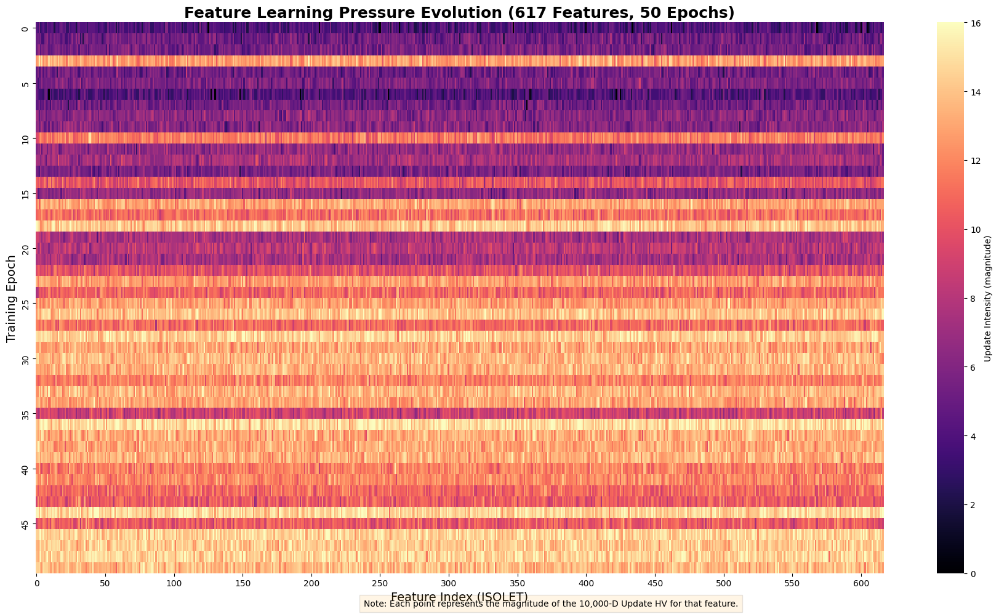

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_update_hv_evolution(update_hv_dict, metric='magnitude'):
    """
    Compresses 617x10,000 sparse Update HVs into an intensity heatmap 
    across epochs to show where the model is 'learning' most.
    
    Args:
        update_hv_dict: Dictionary { 'epoch_0': np.array(617, 10000), ... }
        metric: 'magnitude' (L2 norm) or 'max' (highest single weight)
    """
    # 1. Sort epochs numerically
    epoch_keys = sorted(update_hv_dict.keys(), key=lambda x: int(x.split('_')[1]))
    n_epochs = len(epoch_keys)
    n_features = next(iter(update_hv_dict.values())).shape[0]
    
    # 2. Compression: Transform (617, 10000) -> (617,) for each epoch
    # We want to see how much 'weight' or 'pressure' is at each feature index.
    intensity_matrix = np.zeros((n_epochs, n_features))
    
    print(f"Compressing {n_epochs} epochs of 10,000-D data...")
    
    for i, key in enumerate(epoch_keys):
        update_hv = update_hv_dict[key] # Shape: (617, 10000)
        
        if metric == 'magnitude':
            # L2 Norm: Captures total accumulated weight in the 10k space for that feature
            intensity_matrix[i, :] = np.linalg.norm(update_hv, axis=1)
        elif metric == 'max':
            # Max: Captures the single strongest 'discriminative' bit update
            intensity_matrix[i, :] = np.max(np.abs(update_hv), axis=1)
            
    # 3. Intensity Mapping (Global Normalization)
    v_min = 0
    v_max = np.percentile(intensity_matrix, 99) # Use percentile to ignore extreme outliers
    
    plt.figure(figsize=(18, 10))
    
    # 4. Creating the Heatmap
    # We use 'magma' because unbinarized weights are essentially 'energy'
    ax = sns.heatmap(
        intensity_matrix, 
        cmap='magma', 
        xticklabels=50, 
        yticklabels=max(1, n_epochs // 10),
        vmin=v_min, 
        vmax=v_max,
        cbar_kws={'label': f'Update Intensity ({metric})'},
        rasterized=True # Crucial for performance with 617 features
    )
    
    plt.title(f"Feature Learning Pressure Evolution (617 Features, {n_epochs} Epochs)", fontsize=18, fontweight='bold')
    plt.xlabel("Feature Index (ISOLET)", fontsize=14)
    plt.ylabel("Training Epoch", fontsize=14)
    
    # Add a note about the compression
    plt.figtext(0.5, 0.01, f"Note: Each point represents the {metric} of the 10,000-D Update HV for that feature.", 
                ha="center", fontsize=10, bbox={"facecolor":"orange", "alpha":0.1, "pad":5})

    plt.tight_layout()
    plt.show()

def extract_top_moving_features(intensity_matrix, top_k=10):
    """
    Identifies features whose update intensity increased the most 
    between first and last epoch.
    """
    diff = intensity_matrix[-1] - intensity_matrix[0]
    top_indices = np.argsort(diff)[-top_k:][::-1]
    return top_indices

plot_update_hv_evolution(update_hv_dict=im_updates_dict, metric='magnitude')

Compressing 50 epochs of 10,000-D data...


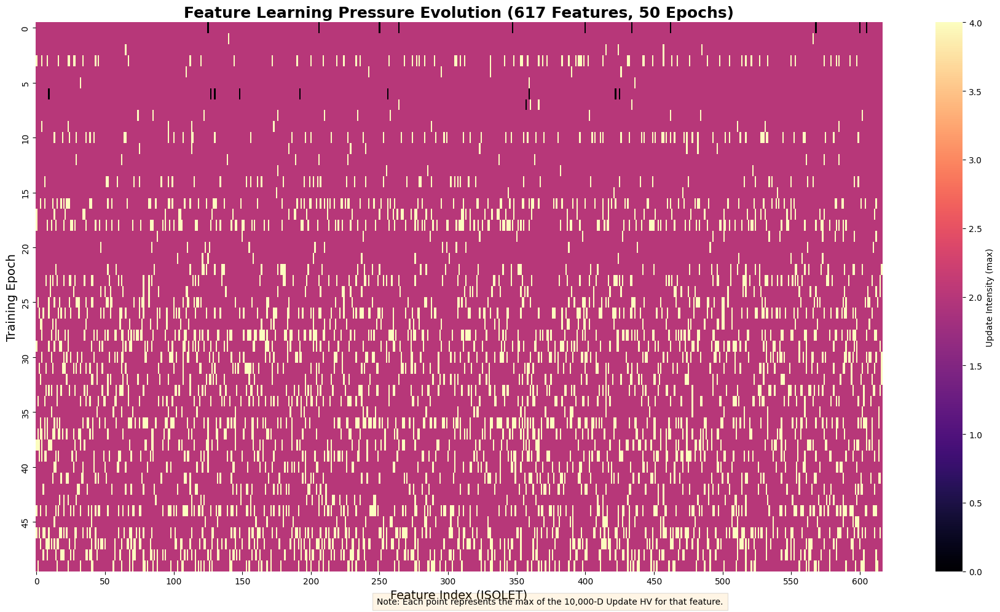

In [43]:
plot_update_hv_evolution(update_hv_dict=im_updates_dict, metric='max')

In [ ]:
# train_accs = [common_func.evaluate_HDC(train_HVs, class_prototypes, train_labels)]
# accs_log = []
# classifier_log = []
# #run training procedure for some number of epochs
# for epoch in range(50):
#     if epoch % 10 == 0 and epoch !=0:
#         print(f"epoch {epoch}")

#         #one iteration of encoder training
#         #get the unbinarized
#         #update class bundles
#         final_class_bundles = common_func.train_classifier_one_iteration(train_HVs, train_labels, class_bundles)

#         #sign class bundles (as before)
#         final_class_prototypes = common_func.rand_sign(final_class_bundles)

#         #evaluate train accuracy (can be used to decide when to stop training, but for now we are just logging it)
#         accs_log.append(common_func.evaluate_HDC(train_HVs, final_class_prototypes, train_labels))
#         classifier_log.append(final_class_prototypes)
        
#         if np.any(accs_log)>0.99: #higher than this is just going to be 1 in a data like this no??
            
#             best_class_prototypes = classifier_log[np.argmax(accs_log)]
#             best_accuracy = np.max(accs_log)#accs_log[np.argmax()]
#             # break #cant do a break cuz the first training accuracy is already high.. i guess that's why he said it wouldnt really matter a lot if i didnt have early stopping in the 
#         else:
#             #reset ??
#             accs_log = []
#             classifier_log = []

    

# #accuracy on the test HV with the "best" version of class prototypes
# final_test_acc = common_func.evaluate_HDC(test_HVs, best_class_prototypes, test_labels)


epoch 10
epoch 20
epoch 30
epoch 40


In [44]:
final_test_acc

0.34830019243104554

Text(0.5, 0, 'Epoch')

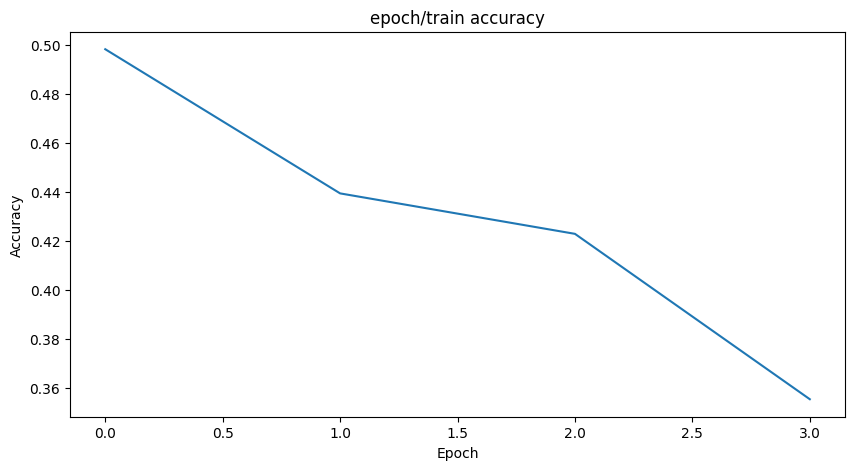

In [ ]:
#train accuracy curve shows that train accuracy improves as training progresses
plt.figure(figsize=(10, 5))
plt.plot(train_accs) #accs_log
plt.title("epoch/train accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")

In [ ]:
print(f"initial test accuracy: {initial_test_acc}")
print(f"final test accuracy:   {final_test_acc}")

initial test accuracy: 0.8672225785760103
final test accuracy:   0.9178960872354073


### Saving the model

In [21]:
#Save the final CIM , IM and Class prototypes ( also referred to as Associated Memory)
model_dict = {'cim':np.array(cim), # cim doesnt change in this set up
              'im':np.array(im_dict['epoch_2']), #im doesnt change in this set up
              'am':np.array(class_prototypes)} #class prototypes go through change during training, but only 1 iteration of training happens
model_dict

{'cim': array([[ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1],
        ...,
        [ 1, -1, -1, ...,  1, -1, -1],
        [ 1, -1, -1, ...,  1, -1, -1],
        [ 1, -1, -1, ...,  1, -1, -1]], dtype=int8),
 'im': array([[ 1, -1,  1, ..., -1,  1,  1],
        [ 1,  1,  1, ..., -1, -1, -1],
        [ 1,  1,  1, ..., -1,  1,  1],
        ...,
        [-1,  1,  1, ..., -1,  1,  1],
        [ 1, -1, -1, ..., -1,  1,  1],
        [-1,  1, -1, ..., -1,  1, -1]], dtype=int8),
 'am': array([[ 1,  1, -1, ..., -1, -1, -1],
        [ 1,  1, -1, ..., -1, -1, -1],
        [ 1,  1, -1, ..., -1, -1, -1],
        [ 1,  1, -1, ..., -1, -1, -1],
        [ 1,  1, -1, ..., -1, -1, -1]], dtype=int8)}

In [22]:
#save model as a pickle file
import pickle as pkl
def save_hdc_model(model,path_w_filename):
    with open(path_w_filename, 'wb') as file:  
        pkl.dump(model, file)

save_hdc_model(model=model_dict,path_w_filename=r"C:\Users\MEGHNA\Documents\2025_college_applications\college_wise_documents\Antwerp\research_project_references\HDVs\intro_code\trained_models\trained_models\\heart\\toy_pamap2_model_2_epoch.pkl")
